In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
raw_data_url="https://raw.githubusercontent.com/faiza-hossain/bangladesh-ecommerce-analytics/refs/heads/main/raw_ecommerce_data.csv"
df=pd.read_csv(raw_data_url)
print("Dataset loaded successfully.")
print("Dataset Shape (Rows, Columns):", df.shape)
df.info()


Dataset loaded successfully.
Dataset Shape (Rows, Columns): (100, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         100 non-null    object 
 1   price_gbp     100 non-null    float64
 2   availability  100 non-null    object 
 3   rating        100 non-null    object 
 4   page_number   100 non-null    int64  
dtypes: float64(1), int64(1), object(3)
memory usage: 4.0+ KB


In [6]:
print("Missing Values:\n",df.isnull().sum())
print("\nDuplicate Rows:",df.duplicated().sum())

rating_map={
    "One":1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}
def extract_rating(val):
  for word,num in rating_map.items():
    if word in str(val):
      return num
  return np.nan
df["rating_numeric"]=df["rating"].apply(extract_rating)

df["is_in_stock"]=df['availability'].apply(lambda x:1 if "In stock" in str(x) else 0)

df[['title','price_gbp','rating','rating_numeric','is_in_stock']].head()

Missing Values:
 title             0
price_gbp         0
availability      0
rating            0
page_number       0
rating_numeric    0
is_in_stock       0
dtype: int64

Duplicate Rows: 0


,title,price_gbp,rating,rating_numeric,is_in_stock
0,A Light in the Attic,51.77,Three,3,1
1,Tipping the Velvet,53.74,One,1,1
2,Soumission,50.10,One,1,1
3,Sharp Objects,47.82,Four,4,1
4,Sapiens: A Brief History of Humankind,54.23,Five,5,1


-----Summary Statistics-----


,price_gbp,rating_numeric
count,100.000000,100.000000
mean,34.560700,2.930000
std,14.638531,1.423149
min,10.160000,1.000000
25%,19.897500,2.000000
50%,34.775000,3.000000
75%,47.967500,4.000000
max,58.110000,5.000000


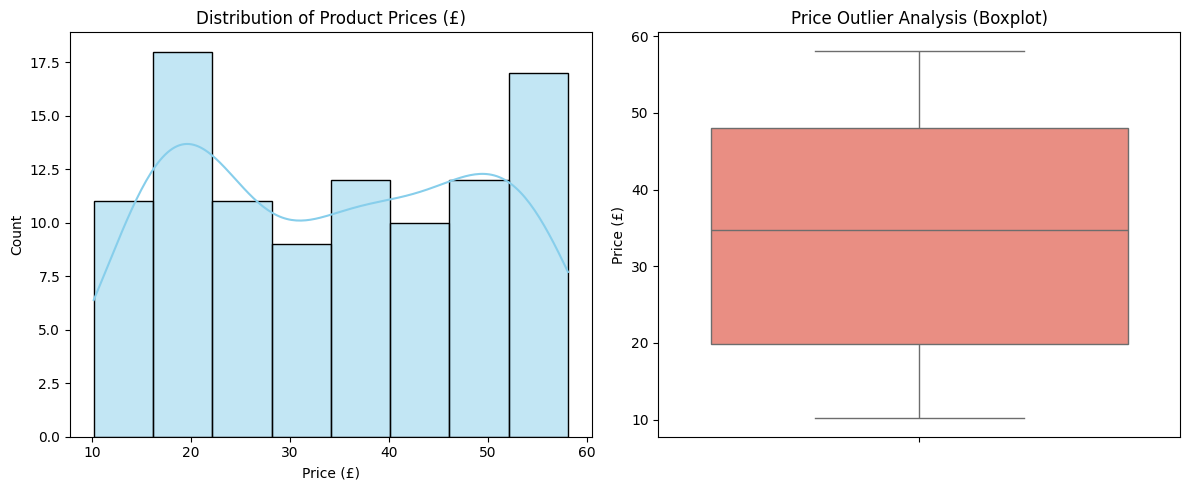

In [7]:
print("-----Summary Statistics-----")
display(df[['price_gbp','rating_numeric']].describe())

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(df['price_gbp'],kde=True, color='skyblue')
plt.title('Distribution of Product Prices (£)')
plt.xlabel('Price (£)')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['price_gbp'], color='salmon')
plt.title('Price Outlier Analysis (Boxplot)')
plt.ylabel('Price (£)')

plt.tight_layout()
plt.show()

--- Price Statistics Grouped by Rating ---


,rating_numeric,count,mean,median,std
0,1,22,35.519545,37.010,15.059933
1,2,19,35.909474,37.320,13.718122
2,3,22,36.839091,37.025,15.759199
3,4,18,33.981667,35.750,15.097152
4,5,19,30.012105,25.270,13.755673


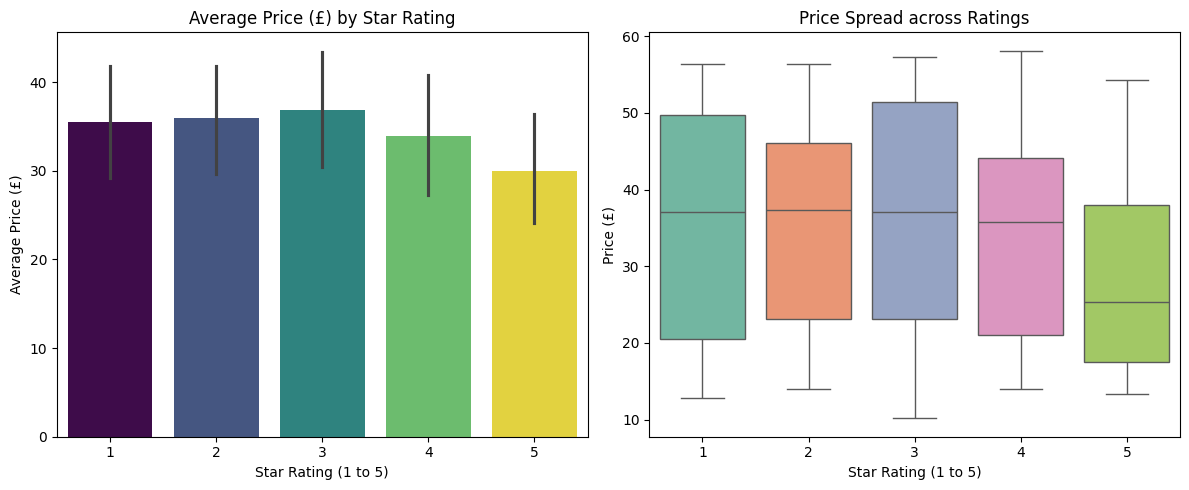

In [10]:
rating_summary=df.groupby('rating_numeric')['price_gbp'].agg(['count','mean','median','std']).reset_index()
print("--- Price Statistics Grouped by Rating ---")
display(rating_summary)

plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
sns.barplot(x='rating_numeric', y='price_gbp', data=df,hue='rating_numeric', palette='viridis', legend=False)
plt.title('Average Price (£) by Star Rating')
plt.xlabel('Star Rating (1 to 5)')
plt.ylabel('Average Price (£)')

plt.subplot(1, 2, 2)
sns.boxplot(x='rating_numeric', y='price_gbp', data=df,hue='rating_numeric' , palette='Set2', legend=False)
plt.title('Price Spread across Ratings')
plt.xlabel('Star Rating (1 to 5)')
plt.ylabel('Price (£)')

plt.tight_layout()
plt.show()

In [11]:
df.to_csv("cleaned_ecommerce_data.csv",index=False)

print(" 'cleaned_ecommerce_data.csv' saved successfully!")
print("Cleaned Dataset Shape:", df.shape)

df.head()

 'cleaned_ecommerce_data.csv' saved successfully!
Cleaned Dataset Shape: (100, 7)


,title,price_gbp,availability,rating,page_number,rating_numeric,is_in_stock
0,A Light in the Attic,51.77,In stock,Three,1,3,1
1,Tipping the Velvet,53.74,In stock,One,1,1,1
2,Soumission,50.10,In stock,One,1,1,1
3,Sharp Objects,47.82,In stock,Four,1,4,1
4,Sapiens: A Brief History of Humankind,54.23,In stock,Five,1,5,1
